In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

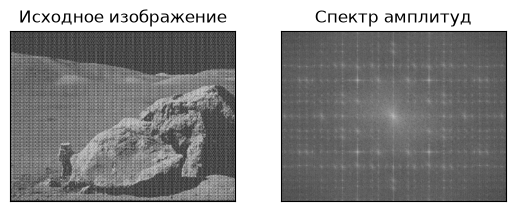

In [2]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
 
dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
 
magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))
 
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Исходное изображение'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Спектр амплитуд'), plt.xticks([]), plt.yticks([])
plt.show()

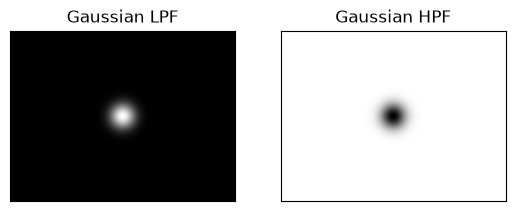

C:\Users\1\AppData\Local\Temp\ipykernel_11828\1424454973.py:31: RuntimeWarning: divide by zero encountered in log
  filtering_magn_res_hp = 20 * np.log(cv.magnitude(dft_shift_hp[:, :, 0],


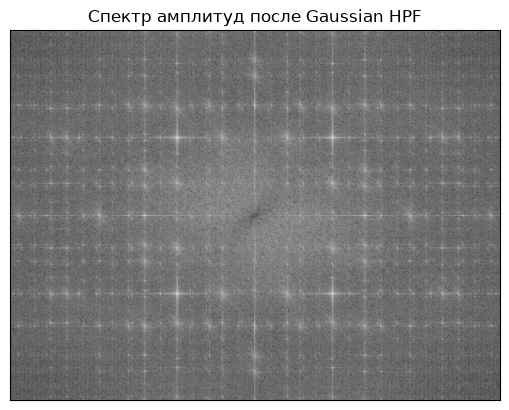

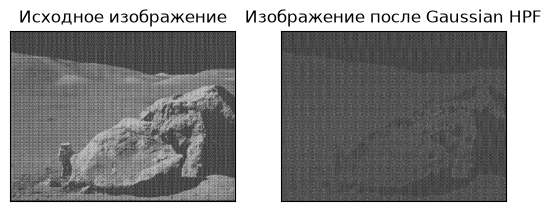

In [3]:
# 1. Высокочастотная фильтрация на основе ядра Гаусса (Gaussian HPF)
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

D0 = 30.0
u = np.arange(rows) - crow
v = np.arange(cols) - ccol
U, V = np.meshgrid(u, v, indexing='ij')
D2 = U**2 + V**2

gauss_low  = np.exp(-D2 / (2 * D0**2))
gauss_high = 1.0 - gauss_low

mask_hp = np.zeros((rows, cols, 2), np.float32)
mask_hp[:, :, 0] = gauss_high
mask_hp[:, :, 1] = gauss_high

# маски
plt.figure()
plt.subplot(121), plt.imshow(gauss_low,  cmap='gray')
plt.title('Gaussian LPF'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(gauss_high, cmap='gray')
plt.title('Gaussian HPF'), plt.xticks([]), plt.yticks([])
plt.show()

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

dft_shift_hp = dft_shift * mask_hp

filtering_magn_res_hp = 20 * np.log(cv.magnitude(dft_shift_hp[:, :, 0],
                                                 dft_shift_hp[:, :, 1]))
plt.figure()
plt.imshow(filtering_magn_res_hp, cmap='gray')
plt.title('Спектр амплитуд после Gaussian HPF')
plt.xticks([]), plt.yticks([])
plt.show()

f_ishift_hp = np.fft.ifftshift(dft_shift_hp)
img_back_hp = cv.idft(f_ishift_hp)
img_back_hp = cv.magnitude(img_back_hp[:, :, 0], img_back_hp[:, :, 1])

# результат
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Исходное изображение'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(img_back_hp, cmap='gray')
plt.title('Изображение после Gaussian HPF'), plt.xticks([]), plt.yticks([])
plt.show()

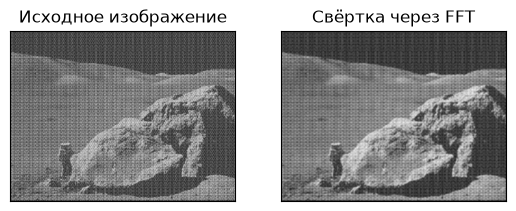

In [4]:
# 2. Вычисление свёртки с помощью преобразования Фурье
kernel_size = 5
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)

def pad_kernel(kernel, shape):
    kh, kw = kernel.shape
    ph, pw = shape
    padded = np.zeros((ph, pw), np.float32)
    padded[:kh//2+1, :kw//2+1]         = kernel[kh//2:, kw//2:]
    padded[:kh//2+1, -(kw//2):]        = kernel[kh//2:, :kw//2]
    padded[-(kh//2):, :kw//2+1]        = kernel[:kh//2, kw//2:]
    padded[-(kh//2):, -(kw//2):]       = kernel[:kh//2, :kw//2]
    return padded

kernel_padded = pad_kernel(kernel, img.shape)

F_img = np.fft.fft2(img)
F_ker = np.fft.fft2(kernel_padded)

F_conv   = F_img * F_ker
conv_fft = np.real(np.fft.ifft2(F_conv))

conv_cv = cv.filter2D(np.float32(img), -1, kernel)

# результат
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Исходное изображение'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(conv_fft, cmap='gray')
plt.title('Свёртка через FFT'), plt.xticks([]), plt.yticks([])
plt.show()

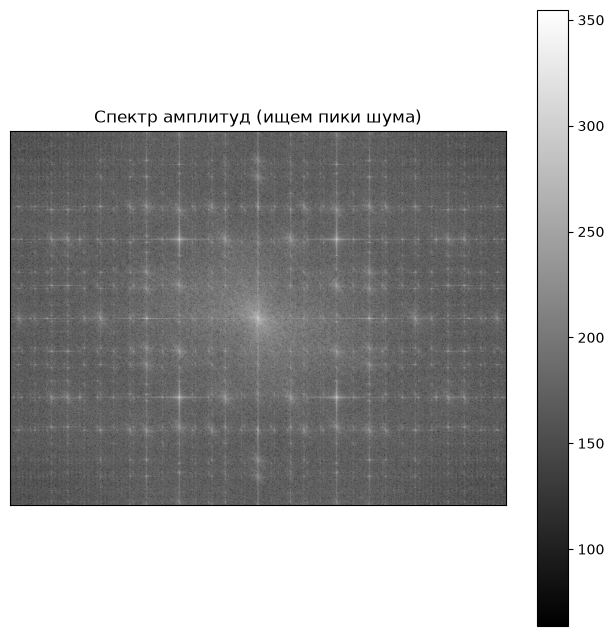

Найденные пики шума (y, x): [(np.int64(297), np.int64(216)), (np.int64(297), np.int64(570)), (np.int64(172), np.int64(518)), (np.int64(422), np.int64(268)), (np.int64(172), np.int64(268)), (np.int64(422), np.int64(518))]


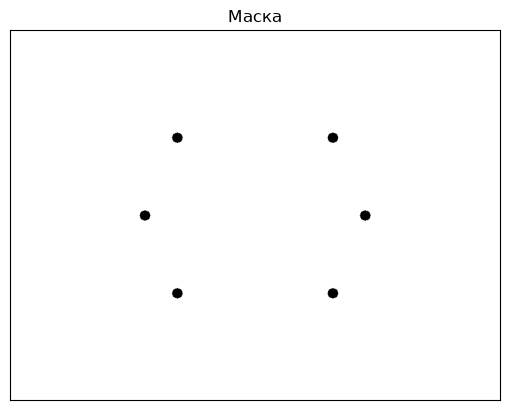

C:\Users\1\AppData\Local\Temp\ipykernel_11828\2388423161.py:58: RuntimeWarning: divide by zero encountered in log
  filtering_magn_res_notch = 20 * np.log(cv.magnitude(dft_shift_notch[:, :, 0],


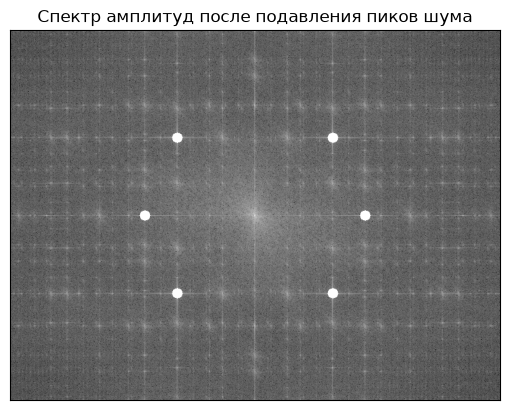

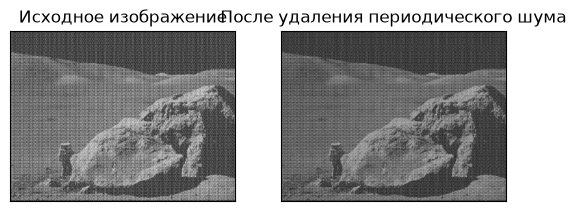

In [5]:
# 3. Удаление периодического шума
dft_noise = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift_noise = np.fft.fftshift(dft_noise)
magnitude_spectrum_noise = 20 * np.log(cv.magnitude(dft_shift_noise[:, :, 0],
                                                    dft_shift_noise[:, :, 1]))

plt.figure(figsize=(8, 8))
plt.imshow(magnitude_spectrum_noise, cmap='gray')
plt.title('Спектр амплитуд (ищем пики шума)')
plt.colorbar()
plt.xticks([]), plt.yticks([])
plt.show()

# автопоиск пиков шума
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2
R_exclude = 40   # не ищем пики в этой окрестности центра (низкие частоты)
R_peak = 8    # радиус зануления вокруг каждого пика
N_peaks = 6    # сколько пиков удаляем

mag = magnitude_spectrum_noise.copy()
Y, X = np.ogrid[:rows, :cols]
center_mask = (Y - crow)**2 + (X - ccol)**2 <= R_exclude**2
mag[center_mask] = mag.min()

peak_coords = []
work = mag.copy()
for _ in range(N_peaks):
    idx = np.argmax(work)
    py, px = np.unravel_index(idx, work.shape)
    peak_coords.append((py, px))
    y0, y1 = max(0, py - R_peak), min(rows, py + R_peak + 1)
    x0, x1 = max(0, px - R_peak), min(cols, px + R_peak + 1)
    work[y0:y1, x0:x1] = work.min()

print('Найденные пики шума (y, x):', peak_coords)

# маска: единицы везде, нули в кругах вокруг пиков ---
mask_notch = np.ones((rows, cols, 2), np.float32)
for (py, px) in peak_coords:
    for (cy, cx) in [(py, px), (rows - py, cols - px)]:
        y0, y1 = max(0, cy - R_peak), min(rows, cy + R_peak + 1)
        x0, x1 = max(0, cx - R_peak), min(cols, cx + R_peak + 1)
        yy, xx = np.ogrid[y0:y1, x0:x1]
        circle = (yy - cy)**2 + (xx - cx)**2 <= R_peak**2
        mask_notch[y0:y1, x0:x1, 0][circle] = 0
        mask_notch[y0:y1, x0:x1, 1][circle] = 0

plt.figure()
plt.imshow(mask_notch[:, :, 0], cmap='gray')
plt.title('Маска')
plt.xticks([]), plt.yticks([])
plt.show()

# применение маски и обратное FFT
dft_shift_notch = dft_shift_noise * mask_notch

filtering_magn_res_notch = 20 * np.log(cv.magnitude(dft_shift_notch[:, :, 0],
                                                     dft_shift_notch[:, :, 1]))
plt.figure()
plt.imshow(filtering_magn_res_notch, cmap='gray')
plt.title('Спектр амплитуд после подавления пиков шума')
plt.xticks([]), plt.yticks([])
plt.show()

f_ishift_notch = np.fft.ifftshift(dft_shift_notch)
img_back_notch = cv.idft(f_ishift_notch)
img_back_notch = cv.magnitude(img_back_notch[:, :, 0], img_back_notch[:, :, 1])

# результат
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Исходное изображение'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(img_back_notch, cmap='gray')
plt.title('После удаления периодического шума'), plt.xticks([]), plt.yticks([])
plt.show()